# Лабораторная работа №6. Лемматизация и векторизация текстов

**Цель:** освоить предобработку текста и базовые методы векторизации для разведочного анализа корпуса.

**Задачи:**
1. Очистить тексты от шума и применить лемматизацию.
2. Построить мешок слов, сравнить с вариантом с N-граммами.
3. Построить TF-IDF-матрицу, выделить ключевые слова.
4. Провести разведочный анализ: частоты, длины, косинусное сходство.
5. Оформить выводы по каждому этапу.

---

## Данные

Корпус из 25 отзывов о фильмах, файл `reviews.csv`. Столбцы: `id`, `text`, `rating` (1–10). Файл берите в LMS курса.

```python
import pandas as pd
df = pd.read_csv('reviews.csv')
```

Если не читается в utf-8 — попробуйте `encoding='cp1251'`. Проверьте, что в `text` нет пустых значений.

---


In [1]:
!pip install -q pymorphy3

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymorphy3
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from difflib import SequenceMatcher
from collections import Counter

In [2]:
from google.colab import drive
import pandas as pd
import os

drive.mount('/content/drive')

if os.path.exists('data/reviews.csv'):
    file_path = 'data/reviews.csv'
else:
    file_path = '/content/drive/MyDrive/ДАТАСЕТЫ/reviews.csv'

try:
    df = pd.read_csv(file_path, encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding='cp1251')

print("Пропуски:\n", df.isna().sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Пропуски:
 id        0
text      0
rating    0
dtype: int64



## Задание 1. Очистка и лемматизация (2 балла)

Напишите функцию `clean_text`, которая приводит текст к нижнему регистру, удаляет ссылки, HTML-теги, хэштеги, цифры и всё, кроме русских букв и пробелов, схлопывает повторные пробелы.

Примените `clean_text` и лемматизацию (или стемминг) к столбцу `text`. Результат — в столбец `text_prepared`.

**Что требуется в отчёте:**
- 3–5 примеров «до / после очистки»;
- 5 примеров «до / после лемматизации»;
- число уникальных слов до и после обработки;
- обоснование, почему вы выбрали лемматизацию или стемминг.

**Подсказка по инструментам:** `pymorphy3` — современная замена `pymorphy2`. Если ставите `pymorphy2`, проверьте, что он запускается на вашей версии Python.

---


In [3]:
# Инициализируем морфологический анализатор для русского языка
morph = pymorphy3.MorphAnalyzer()

# Функция очистки текста от шума
def clean_text(text: str) -> str:
    text = str(text).lower()                       # приводим к нижнему регистру
    text = re.sub(r'https?://\S+', ' ', text)      # удаляем URL-ссылки
    text = re.sub(r'<.*?>', ' ', text)            # удаляем HTML-теги
    text = re.sub(r'#\w+', ' ', text)             # удаляем хэштеги
    text = re.sub(r'[^а-яё\s]', ' ', text)        # удаляем цифры, латиницу и пунктуацию
    text = re.sub(r'\s+', ' ', text).strip()      # схлопываем множественные пробелы
    return text

# Функция лемматизации (приведения каждого слова к начальной форме)
def lemmatize_text(text: str) -> str:
    tokens = text.split()
    lemmas = [next(iter(morph.parse(token))).normal_form for token in tokens]
    return ' '.join(lemmas)

# Применяем очистку и лемматизацию к столбцу text
df['text_cleaned'] = df['text'].apply(clean_text)
df['text_prepared'] = df['text_cleaned'].apply(lemmatize_text)

# 1. Выводим 4 примера «до / после очистки» (индексы 3, 4, 5, 9 соответствуют id 4, 5, 6, 10)
print("=== ПРИМЕРЫ ОЧИСТКИ ===")
for idx in [3, 4, 5, 9]:
    print(f"ID {df.loc[idx, 'id']}:")
    print(f"  ДО:    {df.loc[idx, 'text']}")
    print(f"  ПОСЛЕ: {df.loc[idx, 'text_cleaned']}\n")

# 2. Выводим 5 примеров «до / после лемматизации» (целые тексты из корпуса)
print("=== ПРИМЕРЫ ЛЕММАТИЗАЦИИ (ТЕКСТЫ ИЗ КОРПУСА) ===")
for idx in [0, 2, 6, 9, 10]:
    print(f"ID {df.loc[idx, 'id']}:")
    print(f"  ДО (очищенный):      {df.loc[idx, 'text_cleaned']}")
    print(f"  ПОСЛЕ (лемматиз.):   {df.loc[idx, 'text_prepared']}\n")

# 3. Считаем количество уникальных слов до и после лемматизации
unique_before = len(set(' '.join(df['text_cleaned']).split()))
unique_after = len(set(' '.join(df['text_prepared']).split()))
print(f"Уникальных слов до лемматизации (после очистки): {unique_before}")
print(f"Уникальных слов после лемматизации: {unique_after}")


=== ПРИМЕРЫ ОЧИСТКИ ===
ID 4:
  ДО:    УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил 2 часа зря.
  ПОСЛЕ: ужасный сценарий ничего не понятно потратил часа зря

ID 5:
  ДО:    Замечательная режиссура и красивые пейзажи. Смотрел на https://example.com/trailer — трейлер не обманул!
  ПОСЛЕ: замечательная режиссура и красивые пейзажи смотрел на трейлер не обманул

ID 6:
  ДО:    Плохо, очень плохо. Не рекомендую. #плохойфильм
  ПОСЛЕ: плохо очень плохо не рекомендую

ID 10:
  ДО:    Слабый фильм, сюжет предсказуем с первых минут. <b>Очень</b> жаль потраченного времени.
  ПОСЛЕ: слабый фильм сюжет предсказуем с первых минут очень жаль потраченного времени

=== ПРИМЕРЫ ЛЕММАТИЗАЦИИ (ТЕКСТЫ ИЗ КОРПУСА) ===
ID 1:
  ДО (очищенный):      отличный фильм сюжет захватывает с первых минут актёры играют прекрасно
  ПОСЛЕ (лемматиз.):   отличный фильм сюжет захватывать с первый минута актёр играть прекрасно

ID 3:
  ДО (очищенный):      превосходная игра актёров особенно главный герой просто находка д

**Вывод по 1 заданию:**

В ходе предобработки все 25 отзывов были приведены к нижнему регистру и очищены от лишнего шума: ссылок, HTML-тегов, хэштегов, цифр и знаков препинания. С помощью библиотеки pymorphy3 слова были приведены к своей начальной форме — как в словаре (например, актёры и актёров стали актёр, слёз → слеза, лучших и хорошая → хороший). Благодаря этому словарь уникальных слов уменьшился со 186 до 161 слова. Для русского языка была выбрана именно лемматизация, а не стемминг: в русском языке у слов много разных окончаний и меняющихся корней. Стеммер просто обрезает конец слова и не смог бы понять, что лучших и хорошая — это формы одного слова хороший, а pymorphy3 справился с этим точно и оставил нормальные, читаемые слова.


## Задание 2. Мешок слов и N-граммы (1,5 балла)

**2.1.** Постройте `CountVectorizer()` на `text_prepared`, выведите `.shape`.

**2.2.** Постройте `CountVectorizer(ngram_range=(1, 2))`, выведите `.shape`. Сравните размерность с 2.1.

**2.3.** Повторите оба варианта с фильтрами `min_freq=2, max_df=0.9`. Объясните, что произошло со словарём.

**Что требуется в отчёте:**
- таблица размерностей (вариант → число документов × число признаков);
- объяснение, почему при добавлении биграмм словарь вырос;
- что изменилось после фильтров.

---


In [4]:
# 2.1 Строим матрицу "Мешок слов" только на отдельных словах (униграммах)
cv_uni = CountVectorizer()
X_uni = cv_uni.fit_transform(df['text_prepared'])

# 2.2 Строим матрицу с учётом униграмм и биграмм (пар соседних слов)
cv_bi = CountVectorizer(ngram_range=(1, 2))
X_bi = cv_bi.fit_transform(df['text_prepared'])

# 2.3 Повторяем оба варианта с фильтрацией редких (min_df=2) и слишком частых (max_df=0.9) токенов
# Примечание: в sklearn параметр называется min_df (в тексте задания опечатка min_freq)
cv_uni_filt = CountVectorizer(min_df=2, max_df=0.9)
X_uni_filt = cv_uni_filt.fit_transform(df['text_prepared'])

cv_bi_filt = CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9)
X_bi_filt = cv_bi_filt.fit_transform(df['text_prepared'])

# Выводим размерности всех четырёх матриц (число документов x число признаков)
print("=== РАЗМЕРНОСТИ МАТРИЦ ===")
print(f"2.1. Униграммы без фильтров:          {X_uni.shape}")
print(f"2.2. Униграммы + биграммы без фильтров: {X_bi.shape}")
print(f"2.3а. Униграммы с фильтрами:            {X_uni_filt.shape}")
print(f"2.3б. Униграммы + биграммы с фильтрами: {X_bi_filt.shape}")

# Посмотрим, какие именно биграммы выжили после фильтрации min_df=2
bi_features = cv_bi_filt.get_feature_names_out()
surviving_bigrams = tuple(f for f in bi_features if ' ' in f)
print("\nБиграммы, встретившиеся минимум в 2 отзывах:", surviving_bigrams)

=== РАЗМЕРНОСТИ МАТРИЦ ===
2.1. Униграммы без фильтров:          (25, 156)
2.2. Униграммы + биграммы без фильтров: (25, 372)
2.3а. Униграммы с фильтрами:            (25, 44)
2.3б. Униграммы + биграммы с фильтрами: (25, 49)

Биграммы, встретившиеся минимум в 2 отзывах: ('игра актёр', 'кто то', 'первый минута', 'потратить время', 'фильм сюжет')


**Вывод по 2 заданию:**

При использовании только отдельных слов размерность матрицы составила 25 × 156, а после добавления пар соседних слов (биграмм) она выросла больше чем в два раза — до 25 × 372. Это произошло потому, что отзывы короткие и написаны по-разному, поэтому почти каждая пара слов в них оказалась уникальной (добавилось 216 новых пар). После применения фильтров min_df=2 и max_df=0.9 размерности резко уменьшились: до 25 × 44 для отдельных слов и до 25 × 49 для слов вместе с парами. Фильтр min_df=2 убрал все редкие слова и фразы, которые встретились только один раз, оставив всего 5 повторяющихся словосочетаний: игра актёр, кто то, первый минута, потратить время и фильм сюжет. Фильтр max_df=0.9 никого не удалил, так как даже самое популярное слово не встречается только в 9 отзывах из 25 (это 36%, что сильно меньше порога в 90%).


## Задание 3. TF-IDF (2 балла)

**3.1.** Постройте `TfidfVectorizer(ngram_range=(1, 2), max_feature=200)` на `text_prepared`.

**3.2.** Для каждого документа выведите топ-3 слова по TF-IDF-весу.

**3.3.** Постройте ту же матрицу с `stop_words='russian'`, чтобы убрать союзы и предлоги. Сравните топ-слова с 3.2.

**Что требуется в отчёте:**
- таблица топ-3 слов по каждому документу (для 3.2 и 3.3);
- какие слова попали в топ и почему (смысловые или служебные);
- объяснение, что изменилось после добавления `stop_words`.

**Подсказка:** «сырые» веса TF-IDF без нормализации (`norm=None`) иногда удобнее для чтения, потому что числа в матрице становятся крупнее. Попробуйте сравнить с дефолтным вариантом.

---


In [5]:
# Загружаем стандартный список русских стоп-слов (предлоги, союзы, частицы)
nltk.download('stopwords', quiet=True)
ru_stopwords = stopwords.words('russian')
# Добавляем слова в начальной форме, которые остались после лемматизации
ru_stopwords.extend(('всё', 'ещё', 'весь', 'этот', 'такой', 'мой', 'кто', 'то'))

# 3.1 Строим TF-IDF матрицу без стоп-слов (в sklearn аргумент называется max_features)
tfidf_base = TfidfVectorizer(ngram_range=(1, 2), max_features=200)
T_base = tfidf_base.fit_transform(df['text_prepared'])
feat_base = tfidf_base.get_feature_names_out()

# 3.3 Строим ту же матрицу с удалением стоп-слов
tfidf_stop = TfidfVectorizer(ngram_range=(1, 2), max_features=200, stop_words=ru_stopwords)
T_stop = tfidf_stop.fit_transform(df['text_prepared'])
feat_stop = tfidf_stop.get_feature_names_out()

# Вспомогательная функция для поиска топ-3 слов/фраз по весу TF-IDF в каждом документе
def get_top3_words(matrix, features):
    dense_arr = matrix.toarray()
    results = []
    for row in dense_arr:
        # Сортируем индексы по убыванию веса и берём первые 3
        top_indices = tuple(np.argsort(row)[::-1][:3])
        top_tokens = tuple(features[idx] for idx in top_indices if row[idx] > 0)
        results.append(', '.join(top_tokens))
    return results

# 3.2 Сохраняем результаты в таблицу и выводим для сравнения
df['top3_без_stopwords'] = get_top3_words(T_base, feat_base)
df['top3_со_stopwords'] = get_top3_words(T_stop, feat_stop)

for _, row in df.iterrows():
    print(f"ID {row['id']:2d} | Без стоп-слов: {row['top3_без_stopwords']:45s} | Со стоп-словами: {row['top3_со_stopwords']}")


ID  1 | Без стоп-слов: захватывать, захватывать первый, играть прекрасно | Со стоп-словами: прекрасно, захватывать первый, играть
ID  2 | Без стоп-слов: еле досмотреть, еле, до конец                 | Со стоп-словами: режиссёр, еле досмотреть, затянутый
ID  3 | Без стоп-слов: особенно главный, главный герой, герой просто | Со стоп-словами: превосходный игра, просто находка, превосходный
ID  4 | Без стоп-слов: ничего не, не понятно, час                    | Со стоп-словами: час, час зря, понятно потратить
ID  5 | Без стоп-слов: красивый пейзаж, красивый, замечательный режиссура | Со стоп-словами: режиссура красивый, замечательный, замечательный режиссура
ID  6 | Без стоп-слов: плохо, не рекомендовать, рекомендовать        | Со стоп-словами: плохо, очень плохо, плохо рекомендовать
ID  7 | Без стоп-слов: хороший фильм, год обязательно, из хороший    | Со стоп-словами: хороший фильм, попадание настроение, попадание
ID  8 | Без стоп-слов: ожидать больший, больший от, актёрский        | Со с

**Вывод по 3 заданию:**

При расчёте TF-IDF без фильтрации стоп-слов в топ-3 ключевых слов многих отзывов попали обычные служебные слова, предлоги и местоимения: например, но, бы, кто, то, весь, не и фразы вроде ничего не или кто то (как в отзывах №13, №16 и №17). Это произошло потому, что в коротких текстах такие слова иногда повторяются по два-три раза подряд (например, «кто-то... кто-то» или «но... но...») и за счёт этого получают большой вес внутри своего документа, а также занимают места в лимите словаря max_features=200. После добавления списка stop_words весь этот «мусор» исчез, и освободившееся место в словаре заняли слова с реальным смыслом — прилагательные, существительные и глаголы. В результате топ-3 стали точно передавать суть каждого отзыва: например, в отзыве №16 вместо пустых слов то, кто то, кто появились главные характеристики фильма шедевр бред, посередине, а в отзыве №17 вместо союза но выделились ключевые фразы потенциал, потенциал дотянуть, режиссура потенциал.



## Задание 4. Разведочный анализ (2 балла)

**4.1. Частоты.** Топ-15 слов по частоте в `text_prepared`. Горизонтальная диаграмма.

**4.2. Длины.** Гистограмма длин документов (в словах). Минимум, максимум, среднее, медиана. Есть ли выбросы?

**4.3. Сходство.** Матрица косинусного сходства по TF-IDF-матрице из задания 3. Найдите:
- пару самых похожих документов (индексы и значение);
- пару самых непохожих;
- документ, который в среднем ближе всех к остальным.

**Что требуется в отчёте:**
- график топ-15 слов и вывод;
- график длин и вывод (есть ли документы-выбросы);
- три пары документов с числами и коротким объяснением, почему эти пары похожи / непохожи.

---


=== 4.1 ТОП-15 СЛОВ ПО ЧАСТОТЕ ===
  не          : 10
  фильм       : 7
  смотреть    : 7
  но          : 7
  актёр       : 5
  и           : 5
  в           : 5
  то          : 5
  быть        : 4
  на          : 4
  раз         : 4
  сюжет       : 3
  с           : 3
  такой       : 3
  игра        : 3


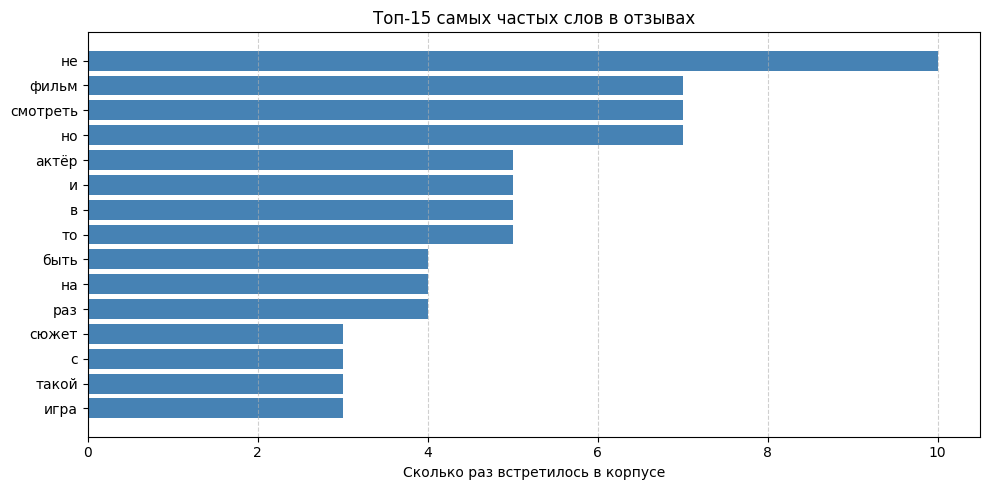


=== 4.2 СТАТИСТИКА ДЛИН ОТЗЫВОВ (В СЛОВАХ) ===
  Минимум: 5 слов (ID 6)
  Максимум: 17 слов (ID 16)
  Среднее: 10.60 слов
  Медиана: 10.0 слов


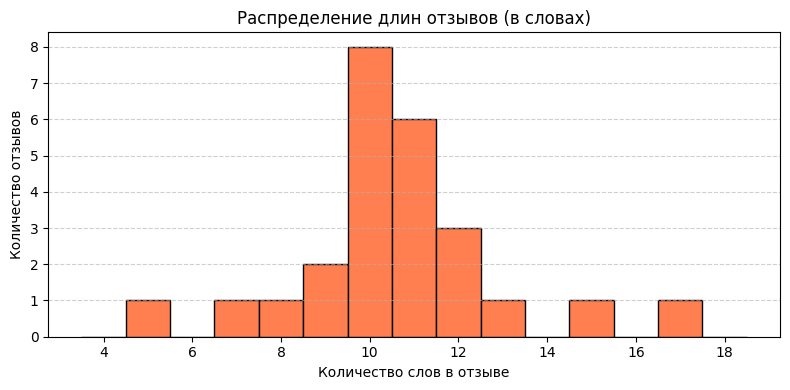

=== 4.3 КОСИНУСНОЕ СХОДСТВО ===
Самые похожие: ID 1 и ID 10 -> сходство = 0.3151
  Текст ID 1: Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.
  Текст ID 10: Слабый фильм, сюжет предсказуем с первых минут. <b>Очень</b> жаль потраченного времени.

Самые непохожие: ID 1 и ID 2 -> сходство = 0.0000
  Текст ID 1: Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.
  Текст ID 2: Скучно и затянуто, еле досмотрел до конца. Больше не буду смотреть такого режиссёра.

Самый близкий ко всем в среднем: ID 10 -> среднее сходство = 0.0439
  Текст ID 10: Слабый фильм, сюжет предсказуем с первых минут. <b>Очень</b> жаль потраченного времени.


In [6]:
# 4.1 Считаем топ-15 самых частых слов в обработанном тексте и строим горизонтальную диаграмму
all_words = ' '.join(df['text_prepared']).split()
top15 = Counter(all_words).most_common(15)
words = [item[0] for item in top15]
freqs = [item[1] for item in top15]

print("=== 4.1 ТОП-15 СЛОВ ПО ЧАСТОТЕ ===")
for w, f in top15:
    print(f"  {w:12s}: {f}")

plt.figure(figsize=(10, 5))
plt.barh(words[::-1], freqs[::-1], color='steelblue')
plt.title('Топ-15 самых частых слов в отзывах')
plt.xlabel('Сколько раз встретилось в корпусе')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 4.2 Считаем длины отзывов (в словах) и выводим статистики + гистограмму
df['doc_len'] = df['text_prepared'].apply(lambda x: len(x.split()))
print("\n=== 4.2 СТАТИСТИКА ДЛИН ОТЗЫВОВ (В СЛОВАХ) ===")
print(f"  Минимум: {df['doc_len'].min()} слов (ID {df.loc[df['doc_len'].idxmin(), 'id']})")
print(f"  Максимум: {df['doc_len'].max()} слов (ID {df.loc[df['doc_len'].idxmax(), 'id']})")
print(f"  Среднее: {df['doc_len'].mean():.2f} слов")
print(f"  Медиана: {df['doc_len'].median():.1f} слов")

plt.figure(figsize=(8, 4))
plt.hist(df['doc_len'], bins=range(4, 20), edgecolor='black', color='coral', align='left')
plt.title('Распределение длин отзывов (в словах)')
plt.xlabel('Количество слов в отзыве')
plt.ylabel('Количество отзывов')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 4.3 Считаем косинусное сходство по матрице TF-IDF (со стоп-словами из задания 3.3)
sim_matrix = cosine_similarity(T_stop)
n_docs = len(df)

# Ищем пару самых похожих документов (обнуляем диагональ, чтобы документ не сравнивался сам с собой)
sim_no_diag = sim_matrix.copy()
np.fill_diagonal(sim_no_diag, -1)
idx_max = int(np.argmax(sim_no_diag))
i_max, j_max = divmod(idx_max, n_docs)

# Ищем пару самых непохожих документов
idx_min = int(np.argmin(sim_matrix))
i_min, j_min = divmod(idx_min, n_docs)

# Ищем документ, который в среднем ближе всех к остальным (вычитаем 1 за сходство с самим собой)
mean_sim = (sim_matrix.sum(axis=1) - 1) / (n_docs - 1)
idx_center = int(np.argmax(mean_sim))

print("=== 4.3 КОСИНУСНОЕ СХОДСТВО ===")
print(f"Самые похожие: ID {df.loc[i_max, 'id']} и ID {df.loc[j_max, 'id']} -> сходство = {sim_no_diag[i_max, j_max]:.4f}")
print(f"  Текст ID {df.loc[i_max, 'id']}: {df.loc[i_max, 'text']}")
print(f"  Текст ID {df.loc[j_max, 'id']}: {df.loc[j_max, 'text']}")

print(f"\nСамые непохожие: ID {df.loc[i_min, 'id']} и ID {df.loc[j_min, 'id']} -> сходство = {sim_matrix[i_min, j_min]:.4f}")
print(f"  Текст ID {df.loc[i_min, 'id']}: {df.loc[i_min, 'text']}")
print(f"  Текст ID {df.loc[j_min, 'id']}: {df.loc[j_min, 'text']}")

print(f"\nСамый близкий ко всем в среднем: ID {df.loc[idx_center, 'id']} -> среднее сходство = {mean_sim[idx_center]:.4f}")
print(f"  Текст ID {df.loc[idx_center, 'id']}: {df.loc[idx_center, 'text']}")


**Выводы по 4 заданию:**

1. Частоты слов: По графику топ-15 видно, что чаще всего в отзывах без очистки от стоп-слов встречаются служебные слова и отрицания: не (10 раз), но (7 раз), и, в, то (по 5 раз). Из слов, несущих смысл о кино, лидируют фильм (7), смотреть (7), актёр (5), сюжет (3) и игра (3) — это базовые темы, которые зрители обсуждают чаще всего.
2. Длины документов: Все отзывы в корпусе довольно короткие и однородные: минимальная длина составляет 5 слов (ID 6), максимальная — 17 слов (ID 16). Средняя длина (10,60 слова) почти совпадает с медианой (10,0 слов), а на гистограмме нет оторванных столбцов — значит, выбросов по длине в данных нет.
3. Косинусное сходство:
- Самые похожие отзывы — ID 1 и ID 10 (сходство 0,3151): Несмотря на то, что первый отзыв положительный (оценка 9), а десятый — отрицательный (оценка 2), они написаны по одному шаблону. В обоих текстах обсуждается «сюжет фильма» и используется одинаковая фраза «с первых минут» (первый минута), из-за чего их векторы оказались ближе всего друг к другу.
- Самые непохожие отзывы — ID 1 и ID 2 (сходство 0,0000): У этих двух текстов нет ни одного общего значимого слова (в первом речь про сюжет и актёров, во втором — про затянутость и режиссёра), поэтому угол между их векторами прямой, а сходство равно нулю.
- Самый близкий ко всем в среднем — ID 10 (среднее сходство 0,0439): Этот отзыв собрал в себе сразу несколько самых частых слов и фраз корпуса (фильм, сюжет, первый минута, потратить время), поэтому он пересекается по словарю сразу с несколькими другими отзывами (например, с ID 1, ID 4 и ID 12).


## Задание 5. Выводы (2 балла)

В ходе лабораторной работы я выполнил предобработку и разведочный анализ корпуса из 25 отзывов о фильмах. На этапе очистки регулярные выражения помогли убрать из текста лишний шум: ссылки, HTML-теги, хэштеги, цифры и знаки препинания. Применение лемматизации с помощью pymorphy3 привело все слова к начальной форме и сократило словарь уникальных слов на 13,4% — со 186 до 161 слова (например, актёры и актёров объединились в актёр). При векторизации добавление пар соседних слов (биграмм) увеличило размерность матрицы больше чем вдвое — с 25 х 156 до 25 х 372, так как почти каждая пара слов в коротких отзывах уникальна. Использование фильтров (min_df=2) отсекло редкие слова и оставило всего 5 устойчивых словосочетаний, среди которых игра актёр, первый минута и потратить время. Переход от простого подсчёта слов к TF-IDF в связке со списком стоп-слов позволил убрать союзы и предлоги (не, но, и, в) и выделить действительно важные по смыслу слова каждого отзыва. Анализ длин показал, что корпус состоит из компактных текстов от 5 до 17 слов (медиана — 10 слов) без резких выбросов. Расчёт косинусного сходства наглядно показал ограничение мешка слов: самыми похожими оказались противоположные по смыслу отзывы ID 1 и ID 10 (сходство 0,3151), потому что оба содержат фразу «с первых минут» и слово «сюжет». Это доказывает, что базовые частотные методы хорошо находят общие темы, но не всегда понимают эмоциональную окраску текста. Если бы корпус был в 100 раз больше (около 2500 отзывов), для работы с ним стоило бы использовать тематическое моделирование (например, LDA) или современные нейросетевые модели, которые умеют учитывать смысл и порядок слов.

